# Hotel Review Sentiment Classification with Transformers

**Nick Hollman | BAN 5753 Exercise 9**

I fine-tuned a pretrained DeBERTa V3 Small model to identify negative hotel reviews. I used this notebook to document the Python syntax and the decisions behind the analysis so I can adapt the workflow to future text classification projects.

## Analysis overview

| Component | What I used |
|---|---|
| Analysis type | Natural language processing (NLP), supervised binary sentiment classification |
| Model approach | Transfer learning through fine-tuning a pretrained transformer encoder |
| Libraries | PyTorch, Hugging Face Transformers and Datasets, pandas, NumPy, scikit-learn, Matplotlib |
| Inputs | English hotel review bodies from TripAdvisor |
| Target | Negative for 1–2 stars, not negative for 3–5 stars |
| Study design | Seven configurations that vary learning rate, batch size and epochs one factor at a time |
| Validation | Fixed, stratified 85/15 split with seed 42 |
| Metrics | Accuracy, plus precision, recall and F1 for negative reviews |

My strongest observed configuration used a learning rate of 3e-5, batch size 16 and two epochs. It reached 95.11% validation accuracy and a negative-class F1 of 0.756 on 225 validation reviews. These results describe this sample and split.

## How I use these notes

I keep the explanation beside the code it describes. Each section covers the syntax, the reason for the step and what I would change for another project. The saved outputs come from my completed Colab run. The detailed annotations were added afterward.

To reproduce this study, I select a Colab GPU, run the installation cell, restart if prompted and run the remaining cells in order. The model training cells take the most computation. Rerunning them starts new training runs.

## 1. Task definition and rationale

I defined the business task as identifying negative hotel reviews so a consulting team can summarize complaints and prioritize hotels for follow-up.

| Overall rating | Target label | Numeric ID |
|---|---|---|
| 1–2 stars | Negative | 1 |
| 3–5 stars | Not negative, including neutral three-star reviews | 0 |

I used ratings as a proxy for sentiment. The model receives the review body as its input. Review volume and the percentage of negative reviews both matter when interpreting counts at the hotel level.

### My notes on defining the prediction

I decide what one row and one prediction represent before preparing the data. In this project, one row is one hotel review and one prediction is a binary sentiment label.

The class names and numeric IDs need to stay consistent across label preparation, model configuration and evaluation. I use 1 for the negative class so the binary precision, recall and F1 calculations evaluate complaint detection.

For another project, I would first define the business action the prediction should support. For example, support tickets could be labeled urgent or routine. If I needed more than two classes, I would update the label mapping, the labeling rule, the number of model outputs and the metric averaging method together.

## 2. Library installation and GPU verification

### My notes on the environment and settings

I install packages before importing them. In Colab, selecting a GPU makes CUDA available to PyTorch. If installation changes a library already imported in the session, I restart the session before continuing.

- `%pip` is a Jupyter command that installs into the active notebook environment. `-q` reduces installation messages.
- `==` requests an exact package version. `>=` and `<` describe an allowed range.
- `transformers[sentencepiece]` requests Transformers and its SentencePiece dependencies.
- `import pandas as pd` assigns a short alias. `from ... import ...` imports particular names from a package.
- Capitalized variable names such as `SEED` and `MAX_LENGTH` mark settings I intend to hold fixed. Python still allows me to change them.

I used `STUDY_SIZE = 1500`, `DEBUG = False`, `MAX_LENGTH = 128` and `SEED = 42` for the recorded study. A Python value of `None` means no fixed study size here. The conditional expression in `sample_size = DEBUG_SIZE if DEBUG else STUDY_SIZE` chooses the applicable sample size.

`Path` represents a filesystem location. The `/` operator joins path components, and `mkdir(parents=True, exist_ok=True)` creates missing folders while allowing an existing directory. `USE_DRIVE` controls whether I mount Google Drive. Local Colab storage is temporary, so I download the outputs or use Drive when I need to retain them.

For another project, I would set a new output location, choose a sample size and token limit, and check the GPU memory requirement. The package pins reflect the environment used for these saved results. Future environments may need compatible version updates.

In [1]:
# Install Colab-compatible Hugging Face packages.
%pip install -q "transformers[sentencepiece]==5.10.1" "datasets==4.8.4" "accelerate>=1.1,<2" "huggingface-hub>=1.32,<2" "fsspec[http]==2025.12.0"

In [2]:
# Release Python objects between model runs.
import gc
# Build folder paths without manually joining slash characters.
from pathlib import Path

# Use plt as the short name for plotting functions.
import matplotlib.pyplot as plt
# Use NumPy to choose classes from arrays of model scores.
import numpy as np
# Use pandas to clean rows and build results tables.
import pandas as pd
# PyTorch handles tensors, gradients and GPU computation.
import torch
# Load Hub data and represent a categorical sentiment target.
from datasets import ClassLabel, Dataset, load_dataset
# Show tables as rich notebook output.
from IPython.display import display
# Display accuracy fractions as percentages on the plots.
from matplotlib.ticker import PercentFormatter
# Compare package versions numerically.
from packaging.version import Version
# Compute metrics for one label per review.
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
# Import the same Hugging Face training components used in the lecture.
from transformers import (
    AutoConfig,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

# Reuse this seed for sampling, splitting and model initialization.
SEED = 42
# Limit fine-tuning to a fixed sample for the Colab runtime budget.
STUDY_SIZE = 1500  # Use None to train and validate on all cleaned reviews.
# False selects the assignment study. True selects the debug subset.
DEBUG = False
# Number of reviews used only when DEBUG is True.
DEBUG_SIZE = 1000
# Maximum token count per review, including special tokens.
MAX_LENGTH = 128
# Enable only if you want to mount Drive and persist output files there.
USE_DRIVE = False
# Keep enabled to measure how well the minority class is detected.
INCLUDE_NEGATIVE_METRICS = True

# Stop early if Colab has no GPU attached.
if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU in Colab, then rerun this cell.")
# Check the PyTorch requirement for loading the model weight file.
if Version(torch.__version__.split("+")[0]) < Version("2.6"):
    raise RuntimeError("Use a Colab GPU runtime with PyTorch 2.6 or newer for the checkpoint's .bin weights.")

print("PyTorch", torch.__version__)
print("GPU", torch.cuda.get_device_name(0))

# Prefer Colab local storage, or the working directory outside Colab.
base_folder = Path("/content") if Path("/content").is_dir() else Path.cwd()
# Mounting Drive is optional and requires an interactive Colab authorization.
if USE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    # Prefer Colab local storage, or the working directory outside Colab.
    base_folder = Path("/content/drive/MyDrive/BAN 5753 - LLM Modules")

# A conditional expression chooses debug size or study size.
sample_size = DEBUG_SIZE if DEBUG else STUDY_SIZE
# Use the sample size in the output folder name.
mode = f"sample_{sample_size}" if sample_size is not None else "full"
# Display the recorded study summary when debug mode is disabled.
if DEBUG:
    # Use the sample size in the output folder name.
    mode = f"debug_{DEBUG_SIZE}"
# Include the metric choice in the folder name.
metric_mode = "all_metrics" if INCLUDE_NEGATIVE_METRICS else "accuracy_only"
# The / operator joins Path components into one folder path.
model_folder = base_folder / "exercise9_hotel_reviews" / f"{mode}_len{MAX_LENGTH}_{metric_mode}"
# Create missing parent directories. Existing folders are accepted.
model_folder.mkdir(parents=True, exist_ok=True)
print("Study folder", model_folder)

PyTorch 2.11.0+cu130
GPU Tesla T4
Study folder /content/exercise9_hotel_reviews/sample_1500_len128_all_metrics


## 3. Dataset loading and exploration

I used `jniimi/tripadvisor-review-rating`, which contains 201,295 English hotel reviews with overall star ratings. The hotel domain matches the intended review classification task. About 9.4% of the source reviews have 1–2 stars, so I inspected class balance before training. [Dataset viewer](https://huggingface.co/datasets/jniimi/tripadvisor-review-rating/viewer) · [Publisher loading instructions](https://github.com/jniimi/tripadvisor_dataset)

The processed dataset lists Apache-2.0 and refers users to the original source conditions. I retain the source attribution when reusing this dataset. [Dataset card](https://huggingface.co/datasets/jniimi/tripadvisor-review-rating) · [Original source](https://www.cs.cmu.edu/~jiweil/html/hotel-review.html) · [Li, Ott and Cardie paper](https://aclanthology.org/D13-1199/)

### My notes on loading and inspecting data

`load_dataset` returns a `DatasetDict`, which maps split names to Hugging Face Dataset objects. `raw_datasets["train"]` selects the publisher's source split. I create my training and validation partitions later. The revision string pins a particular dataset snapshot.

`select_columns(["text", "overall"])` keeps the two fields needed for this analysis. `to_pandas()` converts the Dataset into a pandas DataFrame for cleaning. In pandas, `reviews["overall"]` selects a Series, while `reviews[["text", "overall"]]` selects a DataFrame.

`pd.to_numeric(..., errors="coerce")` converts ratings to numbers and turns invalid values into missing values. `value_counts()` counts each observed rating. `reindex(stars, fill_value=0)` puts the counts in the order 1 through 5 and inserts zero for any absent rating. Dividing the counts by `len(reviews)` produces proportions.

`isin(stars)` tests membership and returns a boolean Series. The tilde in `~ratings.isin(stars)` reverses that Series, and `sum()` counts the True values. This checks missing or invalid ratings before they become targets.

For another dataset, I would inspect its schema and examples, choose the text and target fields, and check missing values and class counts. I would keep ratings and other label-derived fields out of the model inputs.

README.md:   0%|          | 0.00/4.38k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  221MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/201295 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['hotel_id', 'user_id', 'title', 'text', 'overall', 'cleanliness', 'value', 'location', 'rooms', 'sleep_quality', 'stay_year', 'post_date', 'freq', 'review', 'char', 'lang'],
        num_rows: 201295
    })
})
{'hotel_id': Value('int64'), 'user_id': Value('string'), 'title': Value('string'), 'text': Value('string'), 'overall': Value('float64'), 'cleanliness': Value('float64'), 'value': Value('float64'), 'location': Value('float64'), 'rooms': Value('float64'), 'sleep_quality': Value('float64'), 'stay_year': Value('int64'), 'post_date': Value('timestamp[ns]'), 'freq': Value('int64'), 'review': Value('string'), 'char': Value('int64'), 'lang': Value('string')}


,count,share
overall_stars,,
1,8045,0.039966
2,10786,0.053583
3,28216,0.140172
4,67732,0.336481
5,86516,0.429797


Missing or unexpected ratings 0


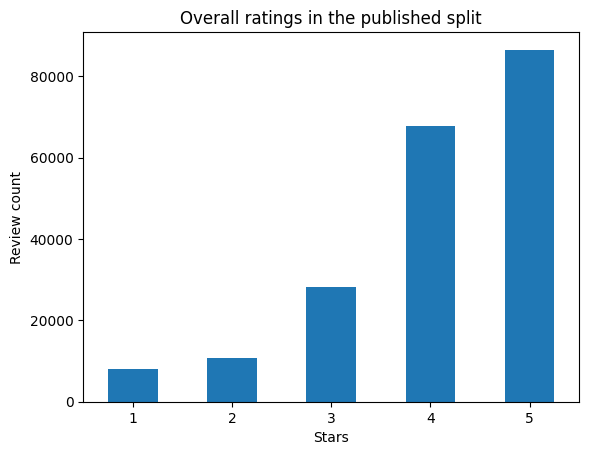

In [3]:
# Load the published Parquet split.
# Use text and overall for this study.
# Hub repository ID for the source hotel review dataset.
dataset_name = "jniimi/tripadvisor-review-rating"
# Pin the source snapshot so future repository updates do not change the data.
dataset_revision = "1a1b7077c997eb496e402c6e9c97d91989eb24bb"
# Download or reuse the cached dataset and return a dictionary of splits.
raw_datasets = load_dataset(dataset_name, revision=dataset_revision)
print(raw_datasets)
print(raw_datasets["train"].features)

# Keep only review bodies and the rating used to build the target.
reviews = raw_datasets["train"].select_columns(["text", "overall"]).to_pandas()
# Convert ratings to numbers and mark invalid numeric values as missing.
ratings = pd.to_numeric(reviews["overall"], errors="coerce")
stars = [1, 2, 3, 4, 5]
# Count ratings and keep the order 1 through 5, including absent categories.
rating_counts = ratings.value_counts().reindex(stars, fill_value=0)
# Create the distribution table. Dividing by row count gives shares.
rating_table = pd.DataFrame({"count": rating_counts, "share": rating_counts / len(reviews)})
display(rating_table.rename_axis("overall_stars"))
print("Missing or unexpected ratings", int((~ratings.isin(stars)).sum()))

ax = rating_counts.plot.bar(rot=0, title="Overall ratings in the published split")
# Label the axis and place ticks at the tested settings.
ax.set(xlabel="Stars", ylabel="Review count")
# Render the figure into the notebook output.
plt.show()

## 4. Labels and training-validation split

I normalized whitespace, removed invalid rows and deduplicated review bodies before splitting. I then sampled 1,500 reviews and created a stratified 85/15 split with seed 42. The saved output shows 1,275 training reviews and 225 validation reviews.

### My notes on cleaning, labels and splitting

The `.str` accessor applies string operations to a pandas column. The raw string `r"\s+"` is a regular expression that matches one or more whitespace characters. `str.replace(..., regex=True)` standardizes those runs to a space, and `str.strip()` removes whitespace at the beginning and end.

I build `valid` as a boolean mask. `fillna("")` treats missing text as an empty string for the check. `ne("")` means not equal to an empty string. The ampersand combines the nonempty-text condition with the valid-rating condition. For pandas Series, I use `&` to combine elementwise conditions.

`.loc[valid, ["text"]]` selects the rows where the mask is True and the text column. `.copy()` creates a separate table. Pandas retains the row index, so `ratings.loc[valid]` aligns the labels with those selected reviews. The comparison `<= 2` returns True or False, and `astype("int64")` converts them into labels 1 and 0.

`casefold()` creates a case-insensitive duplicate key. `groupby(...).transform("nunique")` returns the number of distinct labels in each text group for every row in that group. I remove a group if its labels conflict, then use `drop_duplicates` to keep one consistent example. Doing this before the split reduces duplicate-text leakage.

`enumerate(LABELS)` produces index/name pairs. The dictionary comprehensions create `id2label` and `label2id`. `ClassLabel` marks the target as categorical, which enables this API's stratification option. The first `train_test_split` selects the study sample. The second reserves 15% for validation. Its `"test"` key holds my validation set.

The class-count table uses a dictionary comprehension and `.T` to put the split names in rows. `idxmax()` finds the most frequent training label. I score that majority-label rule on validation data to establish a benchmark. In the print statement, `f"...{value:.2%}"` inserts a number formatted as a percentage.

For another project, I would change the labeling rule and duplicate key to match the data. I would consider splitting by customer, hotel or time if the intended deployment requires that separation. I reload section 3 before rerunning this cleaning cell because it modifies `reviews`.

In [4]:
# Encode one sentiment label per review.
# The position in this list is the numeric class ID.
LABELS = ["not_negative", "negative"]
# Map model output IDs to human-readable class names.
id2label = {i: val for i, val in enumerate(LABELS)}
# Create the reverse mapping for the model configuration.
label2id = {val: i for i, val in enumerate(LABELS)}

# Normalize whitespace before matching duplicate review bodies.
reviews["text"] = reviews["text"].str.replace(r"\s+", " ", regex=True).str.strip()
# Keep rows with nonempty text and ratings in the allowed star categories.
valid = reviews["text"].fillna("").ne("") & ratings.isin(stars)
# Select valid rows while retaining the original row index for label alignment.
reviews = reviews.loc[valid, ["text"]].copy()
# Assign 1 to ratings at most 2 and 0 to ratings 3 through 5.
reviews["labels"] = (ratings.loc[valid] <= 2).astype("int64")
# Compare review bodies case-insensitively when identifying duplicates.
reviews["duplicate_key"] = reviews["text"].str.casefold()
# Flag every row in a text group that has more than one binary label.
conflicts = reviews.groupby("duplicate_key")["labels"].transform("nunique").gt(1)
# Remove conflicting groups and keep one row per remaining review body.
clean_reviews = reviews.loc[~conflicts].drop_duplicates("duplicate_key")
print("Removed missing or invalid examples", int((~valid).sum()))
print("Removed rows with conflicting labels", int(conflicts.sum()))
print("Removed duplicate rows with consistent labels", int((~conflicts).sum() - len(clean_reviews)))

# Convert back to a Hugging Face Dataset without adding an index column.
dataset = Dataset.from_pandas(clean_reviews[["text", "labels"]], preserve_index=False)
# Categorical labels are required for this stratified split API.
dataset = dataset.cast_column("labels", ClassLabel(names=LABELS))
# None means use all cleaned rows. Otherwise select a fixed-size sample.
if sample_size is not None:
    dataset = dataset.train_test_split(
        train_size=sample_size, seed=SEED, stratify_by_column="labels"
    )["train"]

# Reserve 15 percent for validation, preserving the class proportions.
dataset = dataset.train_test_split(test_size=0.15, seed=SEED, stratify_by_column="labels")
print(dataset)
# Build a count table for the two classes in each split.
split_counts = pd.DataFrame({
    name: pd.Series(split["labels"]).value_counts().rename(index=id2label)
    for name, split in [("train", dataset["train"]), ("validation", dataset["test"])]
}).T
display(split_counts.assign(negative_share=split_counts["negative"] / split_counts.sum(axis=1)))
# Find the most common training label using the class-count columns.
majority_label = split_counts.loc["train", LABELS].idxmax()
# Score the rule that predicts the training-majority label for every validation row.
majority_accuracy = split_counts.loc["validation", majority_label] / split_counts.loc["validation"].sum()
print(f"Training-majority rule validation accuracy: {majority_accuracy:.2%}")

Removed missing or invalid examples 0
Removed rows with conflicting labels 0
Removed duplicate rows with consistent labels 41


Casting the dataset:   0%|          | 0/201254 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels'],
        num_rows: 1275
    })
    test: Dataset({
        features: ['text', 'labels'],
        num_rows: 225
    })
})


,not_negative,negative,negative_share
train,1156,119,0.093333
validation,204,21,0.093333


Training-majority rule validation accuracy: 90.67%


## 5. Tokenization and preprocessing

I used the tokenizer associated with DeBERTa V3 Small, truncated each review to 128 tokens and padded each batch dynamically. The shared token limit kept the experiment manageable on the T4.

### My notes on converting text into model inputs

`AutoTokenizer.from_pretrained` loads the tokenizer associated with the saved pretrained model. The model revision keeps the tokenizer and model snapshot consistent. A token can be a word, part of a word or a special marker.

The tokenizer creates `input_ids` and an `attention_mask`. IDs identify tokens in the vocabulary. The attention mask marks positions the model should attend to and padding positions it should ignore. This tokenizer also returns `token_type_ids`.

`def preprocess_function(examples):` defines a function for later use. With `batched=True`, `examples["text"]` is a list of review strings. `return` sends the tokenizer's dictionary back to `map`. Passing `preprocess_function` without parentheses gives `map` the function to call.

`dataset.map` applies that function to both splits. `remove_columns=["text"]` removes the raw text after tokenization. The numeric labels and generated input fields remain available for Trainer.

`truncation=True` enforces the maximum token length, including special tokens. `DataCollatorWithPadding` pads reviews to the longest sequence within each batch so the batch can become a rectangular tensor. One review has one target, so I do not align sentiment labels with individual tokens.

For another text classification project, I would update the text field name and select a tokenizer compatible with the model. I would inspect review lengths before choosing `MAX_LENGTH`, since truncation can remove important text. I would hold that choice fixed while comparing training settings.

In [5]:
# Tokenize review bodies.
# Pad each batch dynamically.
# Use the pretrained model selected for this project.
model_checkpoint = "microsoft/deberta-v3-small"
# Pin the pretrained checkpoint snapshot.
model_revision = "a36c739020e01763fe789b4b85e2df55d6180012"
# Load the text-to-token converter associated with the checkpoint.
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint, revision=model_revision)

# Define the tokenization routine that map will apply later.
def preprocess_function(examples):
    # Convert text lists to token IDs and masks, truncating long reviews.
    return tokenizer(examples["text"], max_length=MAX_LENGTH, truncation=True)

# Tokenize both splits in batches and remove raw text from model inputs.
dataset = dataset.map(preprocess_function, batched=True, remove_columns=["text"])

# Pad variable-length token sequences when Trainer builds a batch.
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print(dataset["train"].column_names)

config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

Map:   0%|          | 0/1275 [00:00<?, ? examples/s]

Map:   0%|          | 0/225 [00:00<?, ? examples/s]

['labels', 'input_ids', 'token_type_ids', 'attention_mask']


## 6. Model initialization

I used DeBERTa V3 Small with a sequence classification head. The bidirectional encoder can represent a review using context from both directions. The classification head produces one score for each sentiment class. [Model card](https://huggingface.co/microsoft/deberta-v3-small) · [DeBERTa V3 paper](https://arxiv.org/abs/2111.09543)

### My notes on the pretrained model and classification head

`AutoConfig.from_pretrained` loads configuration settings. `num_labels=len(LABELS)` gives the head two outputs for this project. The label dictionaries attach readable names to those output IDs.

`AutoModelForSequenceClassification.from_pretrained` loads the pretrained encoder weights and creates the task-specific classification head. A checkpoint means the saved weights for a particular model architecture. The variable `model_checkpoint` identifies the pretrained model I load from the Hub.

`def initialize_model():` defines a factory function. Its body runs when another cell calls `initialize_model()`. Resetting the seed before loading the model helps keep the newly initialized head consistent across experiments. Each run begins with the original pretrained weights.

Missing classification-head or pooler weights in the loading report are expected when those parameters were absent from the original pretraining model. Fine-tuning learns them from the labeled reviews. `dtype=torch.float32` requests 32-bit floating-point weights.

For another project, I would choose an appropriate architecture, update the label mappings and pass the matching configuration and tokenizer. For multiclass classification, I would increase the number of labels and update the metric averaging. The same seed helps reproducibility, although hardware and package versions can still affect results.

In [6]:
# Reset the pretrained model for each run.
# Define a fresh-model factory. The body runs only when called.
def initialize_model():
    # Reset random generators before initializing the classification head.
    set_seed(SEED)
    # Load model settings and specify the binary label mappings.
    config = AutoConfig.from_pretrained(
        model_checkpoint, revision=model_revision, num_labels=len(LABELS),
        id2label=id2label, label2id=label2id,
    )
    # Load pretrained encoder weights and a head for one label per review.
    return AutoModelForSequenceClassification.from_pretrained(
        model_checkpoint, revision=model_revision, config=config, dtype=torch.float32,
    )

## 7. Evaluation metrics

I compared validation accuracy across the required experiments and used negative-class precision, recall and F1 to assess complaint detection. Predicting every review as not negative gives 90.67% accuracy on this validation split.

### My notes on logits and metrics

Trainer passes predictions and labels into `compute_metrics`. The assignment `logits, true_labels = logits_and_labels` unpacks that pair into two variables. For this model, the logits have shape [number of reviews, 2].

`np.argmax(logits, axis=-1)` finds the index of the largest score along the last dimension. It returns one predicted class ID per review. This decision rule does not require converting the scores to probabilities.

| Metric | What it tells me about negative reviews |
|---|---|
| Accuracy | How many of all validation reviews have the correct class |
| Precision | How many reviews flagged as negative are actually negative |
| Recall | How many of the actual negative reviews were detected |
| F1 | The harmonic mean of negative-class precision and recall |

`average="binary"` requests scores for one target class. `pos_label=label2id["negative"]` makes that class negative sentiment, even though the metric API calls it the positive class. The underscore in `precision, recall, f1, _` discards the unused support value. `zero_division=0` returns zero when a metric has an undefined denominator.

`metrics_results` is a dictionary. `.update` adds the optional metrics. Trainer adds the `eval_` prefix when reporting the returned values, which explains keys such as `eval_accuracy`.

For another project, I would choose metrics based on the cost of missed cases and false alarms. For more than two classes, I would replace binary averaging with a suitable multiclass approach. To recover counts from this saved run, I multiply accuracy by 225 for total correct predictions and negative recall by 21 for correctly detected negative reviews.

In [7]:
# Score one prediction per review.
# Trainer calls this function after collecting evaluation predictions.
def compute_metrics(logits_and_labels):
    # Unpack the model score array and the actual class IDs.
    logits, true_labels = logits_and_labels
    # Choose the largest of the two logits in each review row.
    predicted_indices = np.argmax(logits, axis=-1)

    # Start the returned dictionary with overall validation accuracy.
    metrics_results = {"accuracy": accuracy_score(true_labels, predicted_indices)}
    # Add the optional scores for negative-review detection.
    if INCLUDE_NEGATIVE_METRICS:
        # Compute binary metrics and discard the unused support output.
        precision, recall, f1, _ = precision_recall_fscore_support(
            true_labels, predicted_indices, average="binary",
            pos_label=label2id["negative"], zero_division=0,
        )
        # Add precision, recall and F1 to the dictionary.
        metrics_results.update(precision=precision, recall=recall, f1=f1)
    # Trainer reports these keys with the eval_ prefix.
    return metrics_results

## 8. Baseline training and evaluation

I started with a learning rate of 2e-5, training batch size 16 and two epochs. Trainer evaluated the model after each epoch. I used the final trained weights for the comparison and held evaluation batch size at 32.

### My notes on the training function

`run_experiment` accepts four arguments describing a run. I use this shared function to keep the training procedure consistent while changing the selected hyperparameter.

`TrainingArguments` stores the training settings. The keyword on the left of `=` is the API parameter, while the value on the right supplies my choice. For example, `learning_rate=learning_rate` passes the function argument into the training configuration.

| Setting | Why I used it |
|---|---|
| `num_train_epochs` | Controls complete passes through the training split |
| `per_device_train_batch_size` | Sets reviews per training batch on one GPU |
| `gradient_accumulation_steps=1` | Makes each training batch produce an optimizer update |
| `per_device_eval_batch_size=32` | Keeps evaluation batching consistent |
| `optim="adamw_torch"` | Uses PyTorch AdamW to update weights |
| `weight_decay=0.01` | Regularizes applicable model weights |
| `max_grad_norm=1.0` | Clips the gradient norm to limit unusually large updates |
| `eval_strategy="epoch"` | Measures validation performance after each epoch |
| `save_strategy="no"` | Skips periodic checkpoint files across the seven runs |
| `load_best_model_at_end=False` | Keeps the final weights for the epoch-count comparison |
| `fp16=False` | Retains float32 in the recorded experiment |
| `gradient_checkpointing=True` | Reduces activation memory by recomputing intermediate values |
| `report_to="none"` | Disables external services such as Weights & Biases |

`processing_class=tokenizer` and `data_collator=data_collator` tell Trainer how to process and batch the inputs. I pass `dataset["train"]` for weight updates and `dataset["test"]` for validation metrics. The model receives the tokenized inputs and labels.

`trainer.train()` performs fine-tuning. `trainer.evaluate()` measures the final model and returns a metric dictionary. Because evaluation also runs at the end of each epoch, the explicit call repeats the last validation evaluation for the recorded results.

`trainer.save_model` exports the baseline model in this notebook. The strongest measured configuration is recorded in the results table, and its weights would need their own export for deployment.

I return a `record` dictionary with settings and metrics. The loop copies the optional negative-class metrics into that dictionary. An f-string builds keys such as `negative_f1` and `eval_f1`. `del`, `gc.collect()` and `torch.cuda.empty_cache()` help release memory before the next model is loaded.

For another project, I would keep the same train/evaluate structure and change only the settings under study. With one GPU, no dropped final batch and accumulation of one, updates per epoch are the training size divided by batch size, rounded up. My batch sizes of 8, 16 and 32 therefore produced 160, 80 and 40 updates per epoch. Rerunning a training call starts a fresh run. If I need to resume interrupted training, I would explicitly configure checkpoint saving and resumption.

In [8]:
# Define the shared procedure used by all seven configurations.
def run_experiment(run_name, learning_rate, batch_size, num_train_epochs):
    # Give this run its own directory below the study folder.
    output_dir = model_folder / run_name
    # Create the run folder if needed.
    output_dir.mkdir(parents=True, exist_ok=True)

    # Start from pretrained weights, independent of every preceding run.
    model = initialize_model()
    # Describe optimizer, schedule, evaluation, storage and logging choices.
    training_args = TrainingArguments(
        # Number of complete passes through the training split.
        num_train_epochs=num_train_epochs,
        # Training reviews per GPU batch. Accumulation is one in this study.
        per_device_train_batch_size=batch_size,
        # Evaluation batch size stays constant across training comparisons.
        per_device_eval_batch_size=32,
        # AdamW weight decay regularizes applicable model parameters.
        weight_decay=0.01,
        # Set the initial learning rate for this run.
        learning_rate=learning_rate,
        # Use PyTorch AdamW through Trainer.
        optim="adamw_torch",
        # Update once per batch so the physical and effective batch sizes match.
        gradient_accumulation_steps=1,  # One optimizer step per batch.
        output_dir=str(output_dir),
        # Evaluate on the held-out validation split after every epoch.
        eval_strategy="epoch",
        # Disable periodic checkpoints to limit storage across seven runs.
        save_strategy="no",  # Skip periodic checkpoints.
        # Evaluate the final trained weights for the epoch-count comparison.
        load_best_model_at_end=False,
        # Retain float32 training in the recorded experiment.
        fp16=False,
        # Clip the total gradient norm to reduce excessively large updates.
        max_grad_norm=1.0,
        # Recompute some activations during backward to reduce memory use.
        gradient_checkpointing=True,  # Reduce activation memory.
        # Use the non-reentrant activation checkpointing implementation.
        gradient_checkpointing_kwargs={"use_reentrant": False},
        # Report training logs at step intervals.
        logging_strategy="steps",
        # Log once every 20 optimizer steps.
        logging_steps=20,
        # Label logs with the configuration name.
        run_name=run_name,
        # Keep training randomness controlled across configurations.
        seed=SEED,
        # Keep data sampling randomness controlled across configurations.
        data_seed=SEED,
        # Disable external integrations such as Weights & Biases.
        report_to="none",  # Disable external logging.
    )

    # Let Hugging Face manage batching, gradients, optimizer updates and evaluation.
    trainer = Trainer(
        # Supply the freshly initialized model.
        model=model,
        # Supply the training settings.
        args=training_args,
        # Use only the training split for gradient updates.
        train_dataset=dataset["train"],
        # Use the reserved split for measuring validation performance.
        eval_dataset=dataset["test"],
        # Register the metric function defined in section 7.
        compute_metrics=compute_metrics,
        # Use the current tokenizer API supported by this Trainer version.
        processing_class=tokenizer,
        # Use dynamic padding while assembling batches.
        data_collator=data_collator,
    )
    # This call performs the expensive model training in Colab.
    trainer.train()
    # Collect final validation metrics from the trained model.
    results = trainer.evaluate()
    print(results)

    # Export the baseline model when this is an assignment run.
    if run_name == "baseline" and not DEBUG:
        # Write model weights and configuration for later loading.
        trainer.save_model(str(output_dir / "final_model"))
    # Build one dictionary containing the run settings and measured results.
    record = {
        "run": run_name,
        "learning_rate": learning_rate,
        "batch_size": batch_size,
        "num_train_epochs": num_train_epochs,
        "validation_accuracy": results["eval_accuracy"],
        "mode": mode,
        "gpu": torch.cuda.get_device_name(0),
    }
    # Add the optional scores for negative-review detection.
    if INCLUDE_NEGATIVE_METRICS:
        # Copy the optional scores out of the Trainer metric dictionary.
        for metric in ["precision", "recall", "f1"]:
            # Use an f-string to build matching result-column and Trainer-metric names.
            record[f"negative_{metric}"] = results[f"eval_{metric}"]

    # Remove the references that can keep model tensors alive.
    del trainer, model
    # Ask Python to collect unreachable objects.
    gc.collect()
    # Release unused cached GPU memory for the next run.
    torch.cuda.empty_cache()
    # Return one result row to the caller.
    return record

In [9]:
# Tuple order matches the four run_experiment parameters.
baseline_config = ("baseline", 2e-5, 16, 2)
# The asterisk unpacks the tuple into the function arguments.
baseline_results = run_experiment(*baseline_config)
display(pd.DataFrame([baseline_results]))

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  286MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.de

model.safetensors: reconstructing file:   0%|          |  0.00B /  286MB            

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


... (2 outputs left out)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.180478,0.115237,2,0.946667,0.736842,0.666667,0.700000


{'eval_loss': 0.11523664742708206, 'eval_accuracy': 0.9466666666666667, 'eval_precision': 0.7368421052631579, 'eval_recall': 0.6666666666666666, 'eval_f1': 0.7}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,run,learning_rate,batch_size,num_train_epochs,validation_accuracy,mode,gpu,negative_precision,negative_recall,negative_f1
0,baseline,0.00002,16,2,0.946667,sample_1500,Tesla T4,0.736842,0.666667,0.7


## 9. Hyperparameter experiments

I compared learning rates of 1e-5, 2e-5 and 3e-5, batch sizes of 8, 16 and 32, and epoch counts of 1, 2 and 3. The baseline supplies the middle value in each comparison, giving seven unique runs.

### My notes on configurations and unpacking

Each configuration is a tuple containing the run name, learning rate, batch size and epoch count. Their order matches the parameters of `run_experiment`.

- `run_experiment(*config)` expands a tuple into positional arguments.
- `[baseline_config, *experiment_configs]` expands the six configurations beside the baseline.
- `config[1:]` slices off the run name and retains only the numerical settings.
- The set comprehension removes duplicate combinations, and `assert` checks that seven unique configurations remain.

The list comprehension calls the function once for each configuration and collects the returned dictionaries. It runs sequentially. These are independent fine-tuning runs from the same pretrained model.

I hold the split, seed, model and preprocessing fixed. Batch size also changes the number of optimizer steps, and Trainer's linear learning rate schedule spans the steps in that run. Epoch count changes that schedule's length as well.

For another project, I would define a baseline first, select a small range for each parameter and reuse the same validation partition. A parameter search answers which tested setting performed best under that protocol. An independent test set is needed to estimate performance after choosing settings.

In [10]:
# Each tuple changes one baseline factor and gives the run a name.
experiment_configs = [
    ("lr_1e-5", 1e-5, 16, 2),
    ("lr_3e-5", 3e-5, 16, 2),
    ("batch_8", 2e-5, 8, 2),
    ("batch_32", 2e-5, 32, 2),
    ("epochs_1", 2e-5, 16, 1),
    ("epochs_3", 2e-5, 16, 3),
]
# Expand the six experiment tuples alongside the baseline tuple.
all_configs = [baseline_config, *experiment_configs]
# Check that there are seven distinct numerical configurations.
assert len({config[1:] for config in all_configs}) == 7

# Run six independent training calls and collect their result dictionaries.
experiment_results = [run_experiment(*config) for config in experiment_configs]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.de

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.242174,0.202170,0.906667,0.000000,0.000000,0.000000
2,0.227921,0.143874,0.906667,0.000000,0.000000,0.000000


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.227921,0.143874,2,0.906667,0.000000,0.000000,0.000000


{'eval_loss': 0.14387421309947968, 'eval_accuracy': 0.9066666666666666, 'eval_precision': 0.0, 'eval_recall': 0.0, 'eval_f1': 0.0}


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

... (20 outputs left out)

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.de

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.204229,0.262752,0.906667,0.000000,0.000000,0.000000
2,0.187340,0.133040,0.946667,0.695652,0.761905,0.727273
3,0.116236,0.165912,0.937778,0.705882,0.571429,0.631579


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.116236,0.165912,3,0.937778,0.705882,0.571429,0.631579


{'eval_loss': 0.16591210663318634, 'eval_accuracy': 0.9377777777777778, 'eval_precision': 0.7058823529411765, 'eval_recall': 0.5714285714285714, 'eval_f1': 0.631578947368421}


## 10. Results tables and visualization

I combined the seven returned result dictionaries into a DataFrame, saved the table as CSV and plotted each parameter against validation accuracy. The dashed line is the training baseline's validation accuracy.

### My notes on tables and plots

`pd.DataFrame([baseline_results, *experiment_results])` builds a row for each result dictionary. Matching dictionary keys become columns. `to_csv(..., index=False)` writes those columns without adding the pandas row index.

`comparisons` lists the column to plot, its display label and the relevant run names. Inside the loop, `.isin(run_names)` filters the rows and `.sort_values(column)` orders the settings. Those steps prevent unrelated runs or the original table order from distorting the comparison.

`plt.subplots(1, 3, ...)` creates one figure and three axes. `sharey=True` uses the same accuracy scale. `zip(axes, comparisons)` pairs each axis with one comparison specification. The nested tuple on the left of the loop unpacks the column, title and run names.

`ax.plot(..., marker="o")` draws the measured points. `ax.axhline` draws the baseline. `PercentFormatter(xmax=1)` formats fractions as percentages, while `f"{value:.0e}"` displays learning rates in scientific notation. `plt.show()` renders the figure into the notebook.

For another project, I would update the run-name groups if I changed the experiment list, and export results before ending the session. I would compare recall and F1 alongside accuracy when the classes are imbalanced.

,run,learning_rate,batch_size,num_train_epochs,validation_accuracy,mode,gpu,negative_precision,negative_recall,negative_f1
0,baseline,0.00002,16,2,0.946667,sample_1500,Tesla T4,0.736842,0.666667,0.700000
1,lr_1e-5,0.00001,16,2,0.906667,sample_1500,Tesla T4,0.000000,0.000000,0.000000
2,lr_3e-5,0.00003,16,2,0.951111,sample_1500,Tesla T4,0.708333,0.809524,0.755556
3,batch_8,0.00002,8,2,0.942222,sample_1500,Tesla T4,0.681818,0.714286,0.697674
4,batch_32,0.00002,32,2,0.906667,sample_1500,Tesla T4,0.000000,0.000000,0.000000
5,epochs_1,0.00002,16,1,0.906667,sample_1500,Tesla T4,0.000000,0.000000,0.000000
6,epochs_3,0.00002,16,3,0.937778,sample_1500,Tesla T4,0.705882,0.571429,0.631579


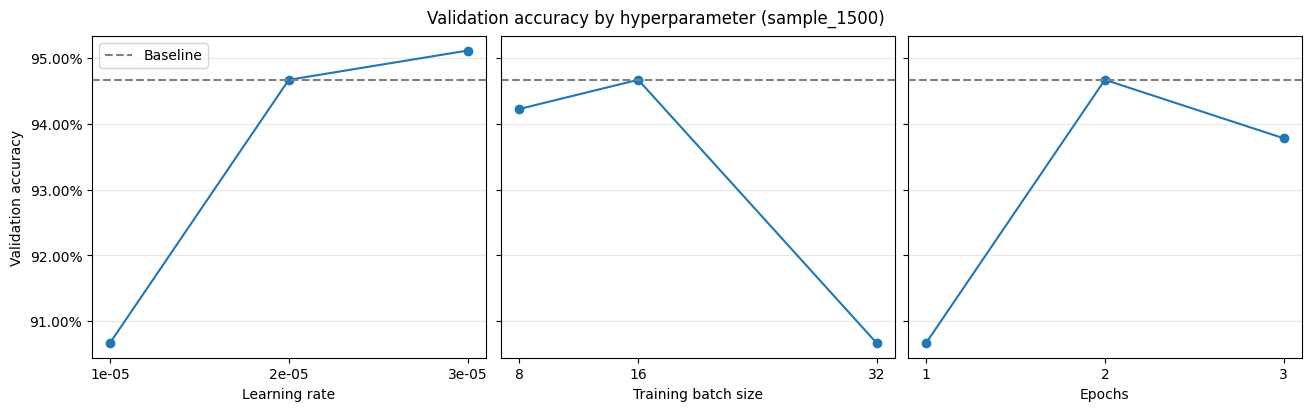

In [11]:
# Combine the baseline and six experiment dictionaries as table rows.
results_df = pd.DataFrame([baseline_results, *experiment_results])
display(results_df)
# Export the measured results without the pandas row index.
results_df.to_csv(model_folder / "validation_results.csv", index=False)

# Specify which three rows belong in each factor comparison.
comparisons = [
    ("learning_rate", "Learning rate", ["baseline", "lr_1e-5", "lr_3e-5"]),
    ("batch_size", "Training batch size", ["baseline", "batch_8", "batch_32"]),
    ("num_train_epochs", "Epochs", ["baseline", "epochs_1", "epochs_3"]),
]
# Create a figure containing three plots with a shared y-axis scale.
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True, layout="constrained")
fig.suptitle(f"Validation accuracy by hyperparameter ({mode})")
# Unpack one plot specification per axis while looping through the comparisons.
for ax, (column, title, run_names) in zip(axes, comparisons):
    # Filter the desired runs and sort by the setting being compared.
    comparison = results_df[results_df["run"].isin(run_names)].sort_values(column)
    # Select the hyperparameter column for the horizontal axis.
    x_values = comparison[column]
    # Plot measured validation accuracy at the tested settings.
    ax.plot(x_values, comparison["validation_accuracy"], marker="o")
    # Draw a reference line at the training baseline accuracy.
    ax.axhline(baseline_results["validation_accuracy"], color="gray", linestyle="--", label="Baseline")
    # Label the axis and place ticks at the tested settings.
    ax.set(xlabel=title, xticks=x_values)
    # Use scientific notation for the small learning-rate values.
    if column == "learning_rate":
        ax.set_xticklabels([f"{value:.0e}" for value in x_values])
    # Show accuracy fractions as percentages.
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Validation accuracy")
axes[0].legend()
# Render the figure into the notebook output.
plt.show()

## 11. Findings and reuse notes

I used 1,275 training reviews and 225 validation reviews. The validation split contained 21 negative reviews.

| Factor | Validation accuracy by setting |
|---|---|
| Learning rate | 1e-5 at 90.67%, 2e-5 at 94.67%, 3e-5 at 95.11% |
| Training batch size | 8 at 94.22%, 16 at 94.67%, 32 at 90.67% |
| Epochs | 1 at 90.67%, 2 at 94.67%, 3 at 93.78% |

The learning rate of 3e-5 with batch size 16 and two epochs gave my highest observed accuracy and negative-class F1. It correctly classified 214 of 225 reviews and detected 17 of 21 negative reviews. The baseline correctly classified 213 reviews and detected 14 negative reviews. Negative-class F1 increased from 0.700 to 0.756, while precision decreased from 73.68% to 70.83%.

The 1e-5, batch size 32 and one-epoch runs scored 90.67% accuracy and detected zero negative reviews. That result reinforced why I need class-specific metrics when evaluating imbalanced data.

These findings describe one small validation split. For a future deployment, I would evaluate the selected model on a separate holdout that reflects the incoming review source.

### What I would update for another project

| Component | Code or setting to revisit |
|---|---|
| Data source | Dataset ID, revision, split names and input columns |
| Target definition | Label rule, class names and numeric mappings |
| Leakage control | Duplicate key and whether rows must be grouped by entity or time |
| Study size | Sample size, class counts and split proportions |
| Pretrained model | Model ID, revision and matching tokenizer |
| Model inputs | Text column and maximum token length |
| Evaluation | Target class, averaging method and business-relevant metrics |
| Experiments | Baseline, configuration tuples and plot groupings |
| Saved artifacts | Output path, results CSV and export of the selected model |

### My notes on interpreting and reproducing the results

The summary cell uses `.max()` to find the largest accuracy and `.eq(best_accuracy)` to select all tied runs. `.loc[mask, "run"]` selects their names. 

Subtracting baseline accuracy from another accuracy gives a fractional difference. Multiplying by 100 expresses it in percentage points. With 225 validation reviews, one correct prediction changes accuracy by about 0.44 percentage points.

The lower learning rate may have adapted too slowly within two epochs. Batch size changes the gradient estimate and update frequency. A third epoch reduced measured accuracy, which could reflect overfitting or variation on this small validation set. The experiment measures the changes but leaves uncertainty about their causes.

To reproduce the study, I run the cells in order with the documented settings and save the outputs and results CSV. I keep the model and data revisions, package versions and GPU details with the results. To reuse the workflow, I update the components listed above and rerun preprocessing, training and evaluation before interpreting new results.

In [12]:
# Display the recorded study summary when debug mode is disabled.
if DEBUG:
    print("Use DEBUG = False for the assignment conclusions.")
else:
    # Read the baseline accuracy for subsequent differences.
    baseline_accuracy = baseline_results["validation_accuracy"]
    print(f"Study size: {len(dataset['train']):,} training and {len(dataset['test']):,} validation reviews")
    # Find the largest measured validation accuracy.
    best_accuracy = results_df["validation_accuracy"].max()
    # Keep every run tied for the largest accuracy.
    best_runs = results_df.loc[results_df["validation_accuracy"].eq(best_accuracy), "run"]
    print(f"Training-majority rule: {majority_accuracy:.2%}")
    print(f"Highest validation accuracy: {best_accuracy:.2%} ({', '.join(best_runs)})")
    # Print a separate factor comparison using the same grouping as the plots.
    for column, title, run_names in comparisons:
        # Filter the desired runs and sort by the setting being compared.
        comparison = results_df.loc[results_df["run"].isin(run_names)].sort_values(column)
        # Convert an accuracy-fraction difference into percentage points.
        delta = 100 * (comparison["validation_accuracy"] - baseline_accuracy)
        print(title)
        display(comparison[[column, "validation_accuracy"]].assign(delta_from_baseline_pp=delta))

Study size: 1,275 training and 225 validation reviews
Training-majority rule: 90.67%
Highest validation accuracy: 95.11% (lr_3e-5)
Learning rate


,learning_rate,validation_accuracy,delta_from_baseline_pp
1,0.00001,0.906667,-4.000000
0,0.00002,0.946667,0.000000
2,0.00003,0.951111,0.444444


Training batch size


,batch_size,validation_accuracy,delta_from_baseline_pp
3,8,0.942222,-0.444444
0,16,0.946667,0.000000
4,32,0.906667,-4.000000


Epochs


,num_train_epochs,validation_accuracy,delta_from_baseline_pp
5,1,0.906667,-4.000000
0,2,0.946667,0.000000
6,3,0.937778,-0.888889
